# AprilTag reliability and localization analysis

**36h11 ID 1 · Arducam B0332 OV9281 · 0.205 m tag · Hamming 0**

This notebook reads the actual per-frame detections and poses from the selected run.
It includes mean distance and angle offsets with **±1 standard deviation**,
detection reliability, position-error distributions and error over time.

**Interpretation:** calibration comes from nominal manufacturer specifications,
an assumed centered crop and zero distortion. These measurements describe the
complete camera/pose/setup pipeline; they do not isolate detector error alone.
The supplied ground-truth pose assumes a level camera and a tag center 0.1075 m
above its optical center. Independent placements were not repeated.

All charts are already rendered below and exported as standalone SVG files.
Rerunning requires NumPy, PyYAML and a normal Python notebook kernel; no plotting package
is required. Change `RUN_DIRECTORY` below to inspect another run.

In [1]:
from pathlib import Path
import csv, json, html, sys
import numpy as np

# Locate the test folder from a notebook, repository, or workspace working directory.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p if (p / 'analysis.py').is_file() and (p / 'results').is_dir()
             else p / 'apriltag_integration_test'
             for p in candidates
             if ((p / 'analysis.py').is_file() and (p / 'results').is_dir())
             or (p / 'apriltag_integration_test' / 'analysis.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the test folder or repository workspace.')

RUN_DIRECTORY = ROOT / 'results' / '20261105T183009_1234fd'
SD_DDOF = 0  # Population standard deviation of recorded frames; use 1 for sample SD.
FIGURES = RUN_DIRECTORY / 'notebook_figures'
FIGURES.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT))
from angle_axes import load_axis_rows, write_angle_axis_reports
rows = load_axis_rows(RUN_DIRECTORY)
if not rows:
    raise ValueError('No per-frame CSV data found in RUN_DIRECTORY.')
if any(r.get('analysis_mode') == 'detection_only' for r in rows):
    raise ValueError('Choose a localization run; detection-only runs have no metric pose errors.')

distances = sorted({r['distance_m'] for r in rows})
groups = [[r for r in rows if r['distance_m'] == d] for d in distances]
labels = [f'{d:g} m' for d in distances] + ['Total average']
all_groups = groups + [rows]
COLORS = ['#2563eb', '#0d9488', '#d97706', '#7c3aed', '#be185d']
notes = sorted({r.get('calibration_basis', 'unspecified') for r in rows})
print(f'Run: {RUN_DIRECTORY.name}')
print(f'{len(rows):,} expected tag observations; {len(distances)} distances; calibration: {", ".join(notes)}')
for report in json.loads((RUN_DIRECTORY / 'summary.json').read_text()):
    print(f"  {Path(report['video']).name}: {report['frames']} frames, "
          f"{report['fps']:.2f} FPS, {report['processed_width']} × {report['processed_height']} pixels")


Run: 20261105T183009_1234fd
1,338 expected tag observations; 3 distances; calibration: manufacturer_specification_estimate
  1.0m.mov: 447 frames, 22.06 FPS, 1200 × 800 pixels
  1.5m.mov: 444 frames, 21.91 FPS, 1200 × 800 pixels
  1.9m.mov: 447 frames, 22.06 FPS, 1200 × 800 pixels


## Definitions and statistical conventions

- **Distance offset:** estimated camera-optical Z depth minus ground truth, in cm.
  Positive means the tag was estimated farther away. It is a signed bias.
- **Horizontal angle offset:** tag-normal azimuth error, positive toward optical +X
  (right). **Vertical angle offset:** tag-normal elevation error, positive upward
  (optical -Y). Both compare estimated orientation with the configured true orientation.
  These are tag tilt errors, not bearing errors of the tag center.
  The forward normal is `n = -R[:,2]` for the installed native tag-frame convention.
  Horizontal = `atan2(nx,nz)`; vertical = `atan2(-ny,hypot(nx,nz))`.
  Errors are wrapped to [-180°,180°). In-plane tag roll is excluded from both axes.
  It is distinct from full 3D rotation error, which also includes other axes.
- **Position error:** 3D camera-position error magnitude in the tag frame, in cm.
  A small depth offset does not imply a small complete localization error.
- Means, SD and percentiles use valid poses. Missing detections stay in the
  detection-rate denominator. A failed pose is not treated as zero error.
- **Total average pools frames**, weighted by each recording's sample count. Its SD
  includes variation between distances and within videos. Its P95 is computed from
  the pooled errors, not by averaging individual P95s.
- **±1 SD is not a confidence interval** or calibration uncertainty. Consecutive
  frames are correlated; this is a descriptive analysis of these recordings.

In [2]:
# Reusable rendering helpers. SVG output stays sharp when exported into a report.
try:
    from IPython.display import display, SVG, HTML
except ImportError:
    display = None

_rendered_outputs = []
def render_svg(svg, filename):
    (FIGURES / filename).write_text(svg)
    _rendered_outputs.append({'image/svg+xml': svg, 'text/plain': filename})
    if display is not None:
        display(SVG(svg))

def render_table(headers, records):
    style = '<style>table.april{border-collapse:collapse;font:14px sans-serif} .april th,.april td{padding:9px 12px;border:1px solid #cbd5e1;text-align:right} .april th{background:#e2e8f0;color:#0f172a} .april td:first-child{text-align:left}</style>'
    body = ''.join('<tr>' + ''.join(f'<td>{html.escape(str(v))}</td>' for v in r) + '</tr>' for r in records)
    result = style + '<table class="april"><thead><tr>' + ''.join(f'<th>{html.escape(h)}</th>' for h in headers) + '</tr></thead><tbody>' + body + '</tbody></table>'
    _rendered_outputs.append({'text/html': result, 'text/plain': str(records)})
    if display is not None:
        display(HTML(result))

def values(samples, metric, scale=1):
    return np.array([r[metric] * scale for r in samples if r['status'] == 'ok'], dtype=float)

def sd(data):
    return float(np.std(data, ddof=SD_DDOF)) if len(data) > SD_DDOF else float('nan')

def base_svg(title, subtitle, width=1000, height=490):
    return [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
            f'<rect width="{width}" height="{height}" fill="white"/>',
            '<g font-family="Arial,sans-serif" fill="#0f172a">',
            f'<text x="75" y="30" font-size="21" font-weight="bold">{html.escape(title)}</text>',
            f'<text x="75" y="54" font-size="13" fill="#475569">{html.escape(subtitle)}</text>']

def axes(parts, ymin, ymax, ylabel, xmin=0, xmax=1, xlabel=''):
    # Plot rectangle: left 85, right 955, top 95, bottom 385.
    xp = lambda v: 85 + (v-xmin)/(xmax-xmin)*870
    yp = lambda v: 385 - (v-ymin)/(ymax-ymin)*290
    for tick in np.linspace(ymin, ymax, 6):
        y = yp(tick)
        parts.append(f'<path d="M85 {y} H955" stroke="#e2e8f0"/>')
        parts.append(f'<text x="73" y="{y+4}" text-anchor="end" font-size="12">{tick:.2f}</text>')
    parts.append('<path d="M85 95 V385 H955" stroke="#475569" fill="none"/>')
    parts.append(f'<text transform="translate(22,245) rotate(-90)" text-anchor="middle" font-size="14">{html.escape(ylabel)}</text>')
    if xlabel:
        for tick in np.linspace(xmin, xmax, 6):
            parts.append(f'<text x="{xp(tick)}" y="407" text-anchor="middle" font-size="12">{tick:.1f}</text>')
        parts.append(f'<text x="520" y="440" text-anchor="middle" font-size="14">{html.escape(xlabel)}</text>')
    if ymin < 0 < ymax:
        parts.append(f'<path d="M85 {yp(0)} H955" stroke="#64748b" stroke-dasharray="5 4"/>')
    return xp, yp

def offset_bars(metric, scale, title, ylabel, filename):
    arrays = [values(g, metric, scale) for g in all_groups]
    if any(not len(a) for a in arrays):
        raise ValueError(f'No valid poses for one of the {metric} groups.')
    means = np.array([a.mean() for a in arrays])
    deviations = np.array([sd(a) for a in arrays])
    low, high = min(0., float(np.min(means-deviations))), max(0., float(np.max(means+deviations)))
    margin = max((high-low)*.22, .3)
    parts = base_svg(title, 'Bars: signed mean offset. Whiskers: mean ±1 SD. Total average: all frames pooled.')
    _, yp = axes(parts, low-margin, high+margin, ylabel)
    xs = np.linspace(175, 865, len(arrays))
    for i, (label, data, mean, deviation, x) in enumerate(zip(labels, arrays, means, deviations, xs)):
        color = '#334155' if i == len(arrays)-1 else COLORS[i % len(COLORS)]
        top, bottom = sorted((yp(mean), yp(0)))
        parts.append(f'<rect x="{x-53}" y="{top}" width="106" height="{max(bottom-top,.5)}" fill="{color}" rx="2"/>')
        yhi, ylo = yp(mean+deviation), yp(mean-deviation)
        parts.append(f'<path d="M{x} {yhi} V{ylo} M{x-12} {yhi} H{x+12} M{x-12} {ylo} H{x+12}" fill="none" stroke="#111827" stroke-width="2"/>')
        parts.append(f'<text x="{x}" y="{min(yhi,yp(mean))-12}" text-anchor="middle" font-size="13" font-weight="bold">{mean:.2f} ± {deviation:.2f}</text>')
        parts.append(f'<text x="{x}" y="410" text-anchor="middle" font-size="14">{html.escape(label)}</text>')
        parts.append(f'<text x="{x}" y="430" text-anchor="middle" font-size="12" fill="#64748b">n = {len(data)}</text>')
    parts.append('<text x="85" y="466" font-size="12" fill="#475569">Descriptive SD only; nominal camera parameters and setup uncertainty are not represented by these whiskers.</text></g></svg>')
    render_svg(''.join(parts), filename)


## 1. Distance offset with ±1 SD

This measures bias along the camera's forward axis. Compare the small within-video
variation with the pooled SD: a stable bias can be repeatable without being accurate.

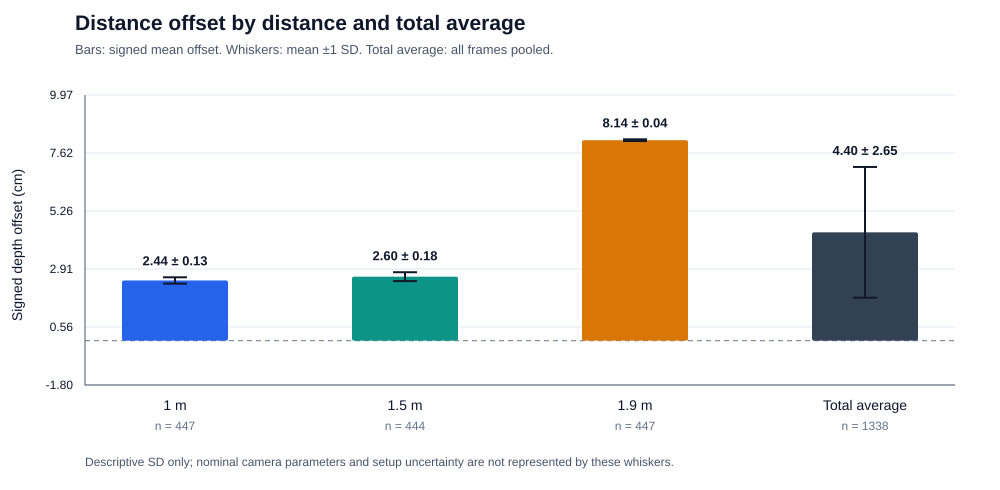

In [3]:
offset_bars('depth_error_m', 100, 'Distance offset by distance and total average', 'Signed depth offset (cm)', 'distance_offset_sd.svg')

## 2. Horizontal angle offset with ±1 SD

These bars use the **signed horizontal angle offset**. The table below also reports
absolute angle errors so opposite signs cannot hide error by cancellation.

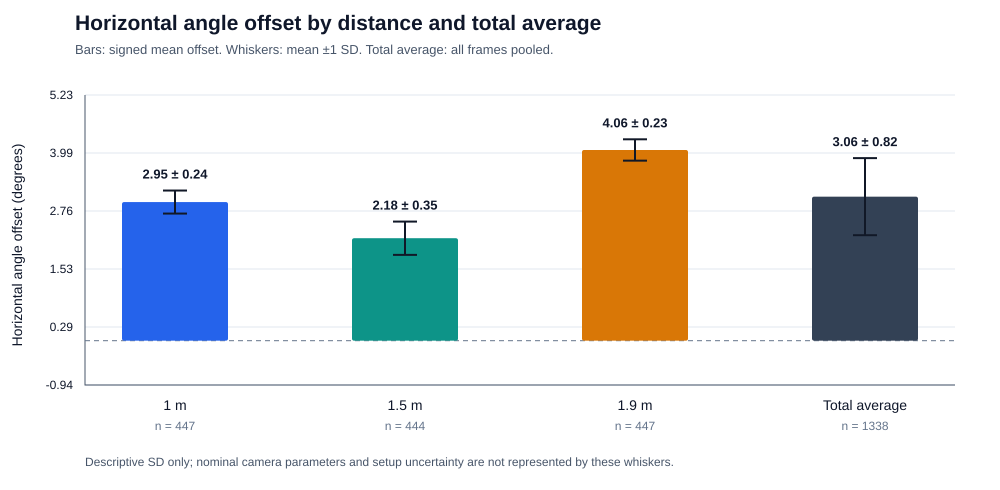

In [4]:
offset_bars('horizontal_angle_error_deg', 1, 'Horizontal angle offset by distance and total average', 'Horizontal angle offset (degrees)', 'angle_offset_sd.svg')

## Horizontal versus vertical angle error

The side-by-side bars show signed mean offsets with **±1 population SD**. The table
and separate CSV also report mean absolute error and P95 absolute error to avoid
hiding errors when signs cancel. The total pools all valid frames. Ground-truth
angles come from each case's configured tag orientation; the existing recordings
assume zero horizontal and vertical tilt. Both axes retain the same nominal
camera-calibration limitations as the other charts.

Summary CSV: /home/ws/apriltag_integration_test/results/20261105T183009_1234fd/horizontal_vertical_angle_errors.csv
Per-frame CSV: /home/ws/apriltag_integration_test/results/20261105T183009_1234fd/horizontal_vertical_angle_errors_frames.csv


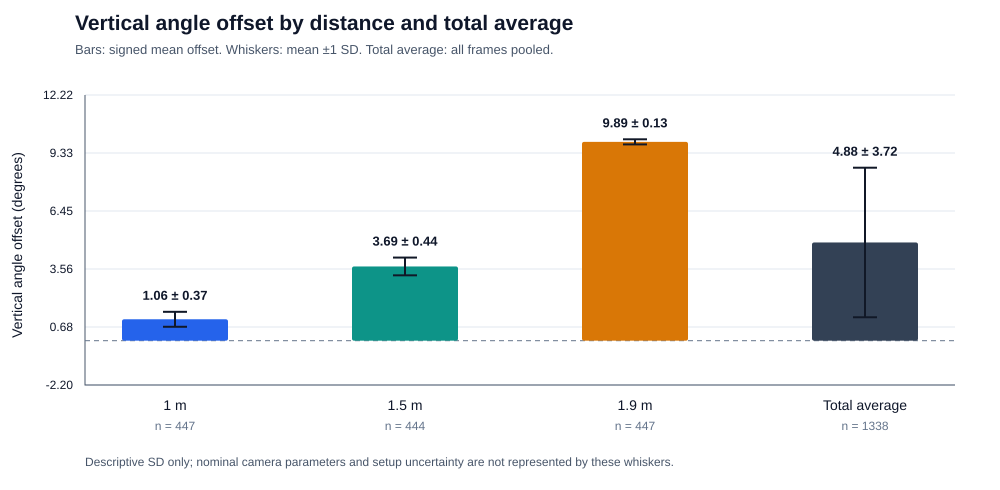

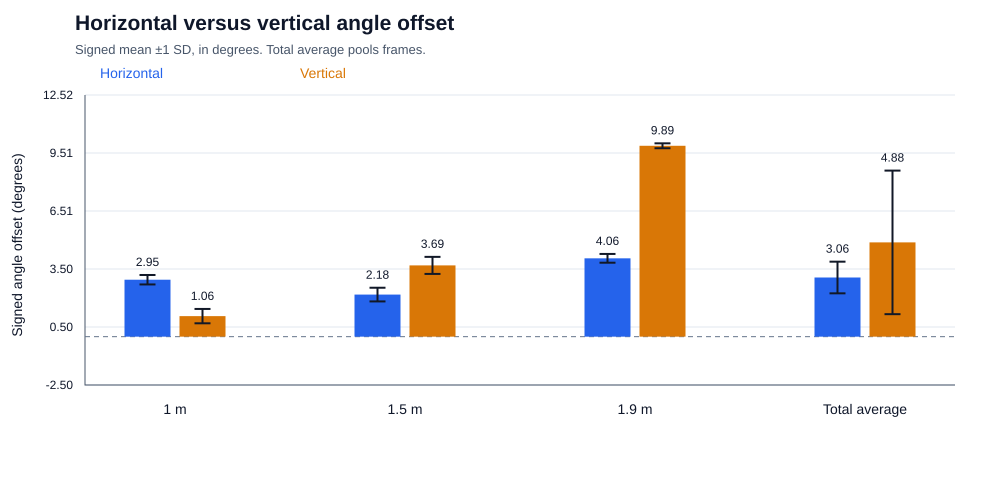

Distance,Horizontal mean ± SD (deg),Horizontal MAE (deg),Horizontal P95 abs (deg),Vertical mean ± SD (deg),Vertical MAE (deg),Vertical P95 abs (deg)
1 m,2.949 ± 0.245,2.949,3.295,1.064 ± 0.372,1.064,1.854
1.5 m,2.180 ± 0.354,2.180,2.708,3.691 ± 0.442,3.691,4.415
1.9 m,4.057 ± 0.227,4.057,4.435,9.886 ± 0.127,9.886,10.084
Total average,3.064 ± 0.820,3.064,4.307,4.883 ± 3.718,4.883,10.021


In [5]:
axis_summary = write_angle_axis_reports(RUN_DIRECTORY, rows, ddof=SD_DDOF)
offset_bars('vertical_angle_error_deg', 1, 'Vertical angle offset by distance and total average',
            'Vertical angle offset (degrees)', 'vertical_angle_offset_sd.svg')

axis_metrics = ['horizontal_angle_error_deg', 'vertical_angle_error_deg']
axis_colors = ['#2563eb', '#d97706']
arrays = [[values(g, metric) for g in all_groups] for metric in axis_metrics]
means = [[a.mean() for a in series] for series in arrays]
deviations = [[sd(a) for a in series] for series in arrays]
low = min(0., min(m-s for series, errors in zip(means,deviations) for m,s in zip(series,errors)))
high = max(0., max(m+s for series, errors in zip(means,deviations) for m,s in zip(series,errors)))
padding = max((high-low)*.25,.3)
parts = base_svg('Horizontal versus vertical angle offset', 'Signed mean ±1 SD, in degrees. Total average pools frames.')
_, yp = axes(parts, low-padding, high+padding, 'Signed angle offset (degrees)')
for j, (name,color) in enumerate(zip(['Horizontal','Vertical'],axis_colors)):
    parts.append(f'<text x="{100+j*200}" y="78" fill="{color}" font-size="14">{name}</text>')
for i,(label,x) in enumerate(zip(labels,np.linspace(175,865,len(all_groups)))):
    for j,color in enumerate(axis_colors):
        center = x + (j-.5)*55
        mean,deviation = means[j][i],deviations[j][i]
        top,bottom = sorted((yp(mean),yp(0)))
        parts.append(f'<rect x="{center-23}" y="{top}" width="46" height="{max(bottom-top,.5)}" fill="{color}"/>')
        yhi,ylo = yp(mean+deviation),yp(mean-deviation)
        parts.append(f'<path d="M{center} {yhi} V{ylo} M{center-8} {yhi} H{center+8} M{center-8} {ylo} H{center+8}" stroke="#111827" stroke-width="2" fill="none"/>')
        parts.append(f'<text x="{center}" y="{min(yhi,yp(mean))-9}" text-anchor="middle" font-size="12">{mean:.2f}</text>')
    parts.append(f'<text x="{x}" y="414" text-anchor="middle" font-size="14">{label}</text>')
parts.append('</g></svg>')
render_svg(''.join(parts),'horizontal_vertical_angle_comparison.svg')

axis_table = []
for label,samples in zip(labels,all_groups):
    record = [label]
    for metric in axis_metrics:
        data = values(samples,metric)
        record.extend([f'{data.mean():.3f} ± {sd(data):.3f}', f'{np.abs(data).mean():.3f}',
                       f'{np.percentile(np.abs(data),95):.3f}'])
    axis_table.append(record)
render_table(['Distance','Horizontal mean ± SD (deg)','Horizontal MAE (deg)',
              'Horizontal P95 abs (deg)','Vertical mean ± SD (deg)',
              'Vertical MAE (deg)','Vertical P95 abs (deg)'], axis_table)
print('Summary CSV:', RUN_DIRECTORY / 'horizontal_vertical_angle_errors.csv')
print('Per-frame CSV:', RUN_DIRECTORY / 'horizontal_vertical_angle_errors_frames.csv')


## 3. Compact numerical summary

Position error includes all three spatial axes. P95 means 95% of valid poses had
error at or below the displayed value. Detection percentages include all samples.

In [6]:
table = []
for label, samples in zip(labels, all_groups):
    depth = values(samples, 'depth_error_m', 100)
    position = values(samples, 'position_error_m', 100)
    angle = np.abs(values(samples, 'angle_error_deg'))
    detection = 100*sum('decision_margin' in r for r in samples)/len(samples)
    table.append([label, len(samples), f'{detection:.2f}',
                  f'{depth.mean():.3f} ± {sd(depth):.3f}',
                  f'{position.mean():.3f}', f'{np.percentile(position,95):.3f}',
                  f'{angle.mean():.3f}', f'{np.percentile(angle,95):.3f}'])
render_table(['Distance', 'Samples', 'Detected (%)', 'Depth mean ± SD (cm)',
              'Mean 3D position error (cm)', 'P95 position error (cm)',
              'Mean absolute angle error (deg)', 'P95 angle error (deg)'], table)


Distance,Samples,Detected (%),Depth mean ± SD (cm),Mean 3D position error (cm),P95 position error (cm),Mean absolute angle error (deg),P95 angle error (deg)
1 m,447,100.00,2.445 ± 0.128,10.300,10.545,2.949,3.295
1.5 m,444,100.00,2.598 ± 0.180,10.839,12.006,2.180,2.708
1.9 m,447,100.00,8.137 ± 0.035,18.289,18.942,4.057,4.435
Total average,1338,100.00,4.397 ± 2.653,13.148,18.736,3.064,4.307


## 4. Detection reliability

Detection success and pose availability are separate checks. High detection rate
does not establish low position error. These percentages describe the supplied
positive clips; they do not measure false-positive rate on scenes without tags.

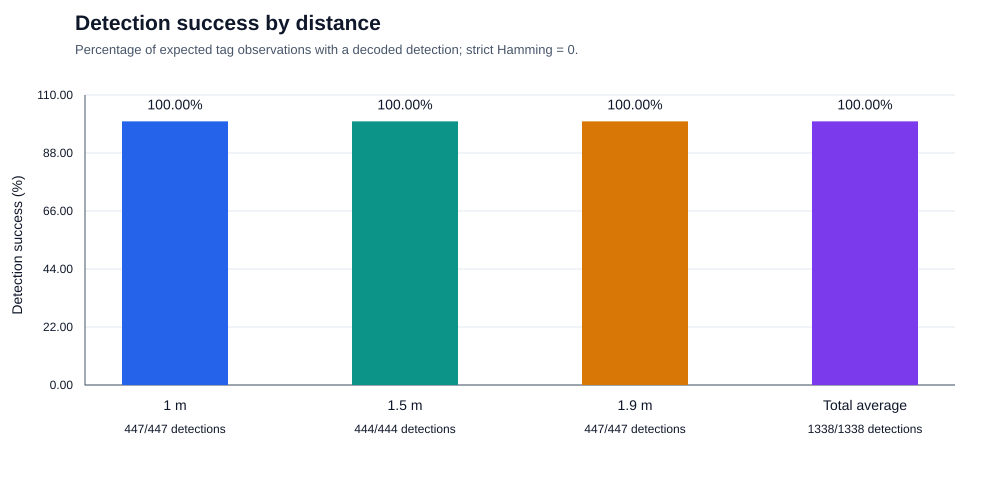

In [7]:
parts = base_svg('Detection success by distance', 'Percentage of expected tag observations with a decoded detection; strict Hamming = 0.')
_, yp = axes(parts, 0, 110, 'Detection success (%)')
for i, (label, samples, x) in enumerate(zip(labels, all_groups, np.linspace(175,865,len(all_groups)))):
    count = sum('decision_margin' in r for r in samples)
    rate = 100*count/len(samples)
    parts.append(f'<rect x="{x-53}" y="{yp(rate)}" width="106" height="{yp(0)-yp(rate)}" fill="{COLORS[i%len(COLORS)]}"/>')
    parts.append(f'<text x="{x}" y="{yp(rate)-12}" text-anchor="middle" font-size="14">{rate:.2f}%</text>')
    parts.append(f'<text x="{x}" y="410" text-anchor="middle" font-size="14">{label}</text>')
    parts.append(f'<text x="{x}" y="433" text-anchor="middle" font-size="12">{count}/{len(samples)} detections</text>')
parts.append('</g></svg>')
render_svg(''.join(parts), 'detection_success.svg')


## 5. Distribution of full 3D position error

The cumulative distribution shows both typical error and the tail. A curve farther
left has smaller errors. The dotted 95% line marks where to read each distance's P95.
Pooling distances can hide a worse condition, so the individual curves stay separate.

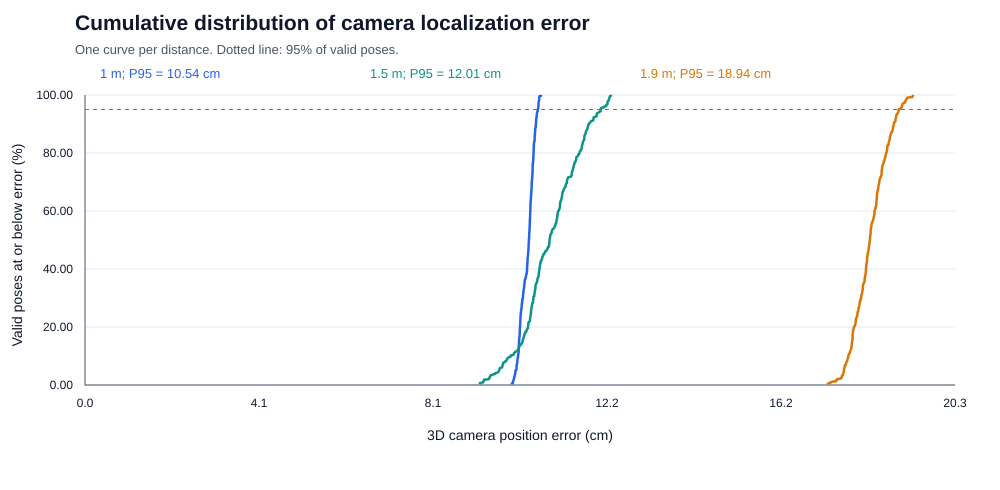

In [8]:
parts = base_svg('Cumulative distribution of camera localization error', 'One curve per distance. Dotted line: 95% of valid poses.')
xmax = max(float(values(g,'position_error_m',100).max()) for g in groups)*1.05
xp, yp = axes(parts, 0, 100, 'Valid poses at or below error (%)', 0, xmax, '3D camera position error (cm)')
parts.append(f'<path d="M85 {yp(95)} H955" stroke="#64748b" stroke-dasharray="4 4"/>')
for i, (distance, samples) in enumerate(zip(distances,groups)):
    data = np.sort(values(samples, 'position_error_m', 100))
    percentage = np.arange(1,len(data)+1)/len(data)*100
    points = ' '.join(f'{xp(x):.2f},{yp(y):.2f}' for x,y in zip(data,percentage))
    color = COLORS[i%len(COLORS)]
    parts.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2.5"/>')
    parts.append(f'<text x="{100+i*270}" y="78" font-size="13" fill="{color}">{distance:g} m; P95 = {np.percentile(data,95):.2f} cm</text>')
parts.append('</g></svg>')
render_svg(''.join(parts), 'position_error_ecdf.svg')


## 6. Error over time: stability versus bias

A narrow but displaced trace indicates stable bias. Drift, jumps or spikes suggest
motion, blur, pose ambiguity or changing image conditions. Missing poses are shown
as gaps. Each clip begins at its own time zero; time is frame index divided by the
recorded nominal FPS, not a measured processing-latency trace.

Standalone SVG charts saved to: /home/ws/apriltag_integration_test/results/20261105T183009_1234fd/notebook_figures


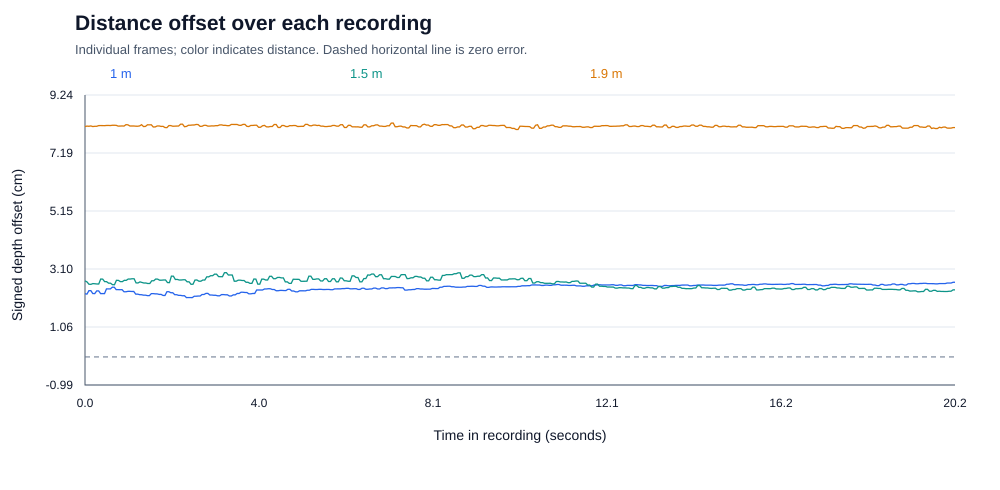

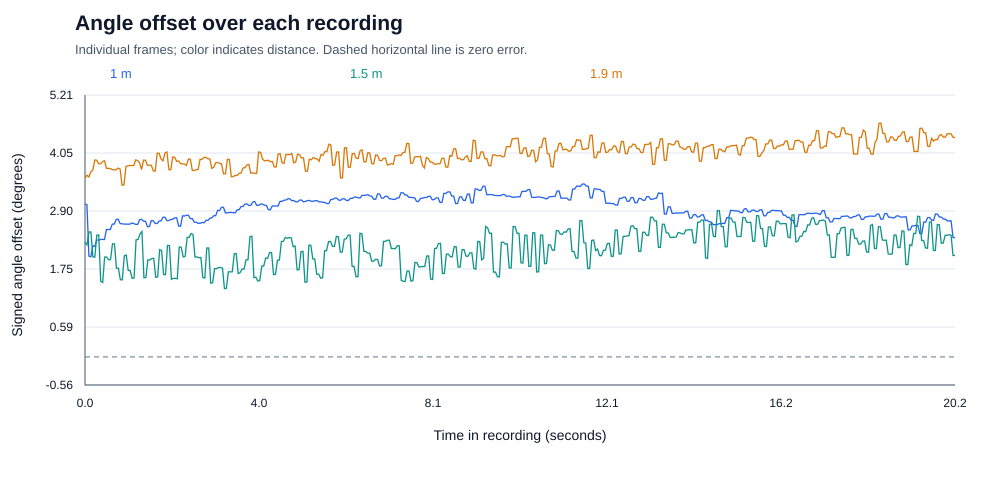

In [9]:
for metric, scale, title, units, filename in [
    ('depth_error_m',100,'Distance offset over each recording','Signed depth offset (cm)','distance_offset_time.svg'),
    ('angle_error_deg',1,'Angle offset over each recording','Signed angle offset (degrees)','angle_offset_time.svg')]:
    arrays = [values(g,metric,scale) for g in groups]
    low = min(0.,min(float(a.min()) for a in arrays))
    high = max(0.,max(float(a.max()) for a in arrays))
    padding = max((high-low)*.12,.1)
    xmax = max(r['video_time_s'] for r in rows)
    parts = base_svg(title, 'Individual frames; color indicates distance. Dashed horizontal line is zero error.')
    xp, yp = axes(parts,low-padding,high+padding,units,0,xmax,'Time in recording (seconds)')
    for i,(distance,samples) in enumerate(zip(distances,groups)):
        color = COLORS[i%len(COLORS)]
        parts.append(f'<text x="{110+i*240}" y="78" font-size="13" fill="{color}">{distance:g} m</text>')
        segment = []
        # Separate clips if multiple cases share a distance; split on missing poses.
        by_case = {}
        for r in samples:
            by_case.setdefault(r['case'],[]).append(r)
        for case in by_case.values():
            segment = []
            for r in sorted(case,key=lambda r:r['frame']):
                if r['status'] == 'ok':
                    segment.append(f"{xp(r['video_time_s']):.2f},{yp(r[metric]*scale):.2f}")
                elif segment:
                    parts.append(f'<polyline points="{" ".join(segment)}" fill="none" stroke="{color}" stroke-width="1.3"/>')
                    segment = []
            if segment:
                parts.append(f'<polyline points="{" ".join(segment)}" fill="none" stroke="{color}" stroke-width="1.3"/>')
    parts.append('</g></svg>')
    render_svg(''.join(parts),filename)
print(f'Standalone SVG charts saved to: {FIGURES}')


## 7. Best-fit angle baselines and detrended variation

Your hypothesis is plausible: a consistently displaced trace can reflect setup or
calibration bias plus smaller frame-to-frame variation. We can describe that pattern
without assuming its cause.

For **each recording, tag and axis separately**, fit `angle_error(t) = a + b*t`
by ordinary least squares. The fitted line captures the recording's offset and
linear drift. The second chart plots `residual(t) = angle_error(t) - fitted_line(t)`.
Both horizontal and vertical errors are analyzed; measurements are not pooled
across recordings before fitting.

**Important distinction:** subtracting a constant offset does **not** change a
recording's SD. Its raw SD already excludes the constant mean. A smaller detrended
SD means the fitted time drift was also removed. Subtracting a separate offset from
each clip can substantially reduce the *pooled* SD, because between-setup biases
are no longer included. These residuals describe repeatability after fitting; they
are not corrected accuracy or proof of human setup error. Fitting can also absorb
real motion or detector drift. Original errors and earlier charts remain unchanged.

The fit is estimated from the same samples being displayed. Residual SD below is
the descriptive population SD, consistent with the other plots, not a confidence
interval or an unbiased estimate based on independent repeats.

Diagnostic exports: angle_detrending_summary.csv and angle_detrending_frames.csv


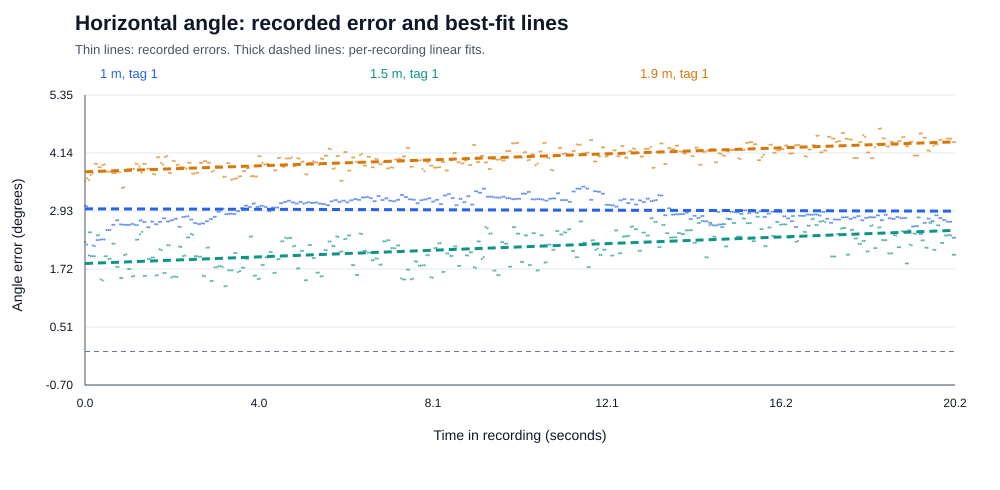

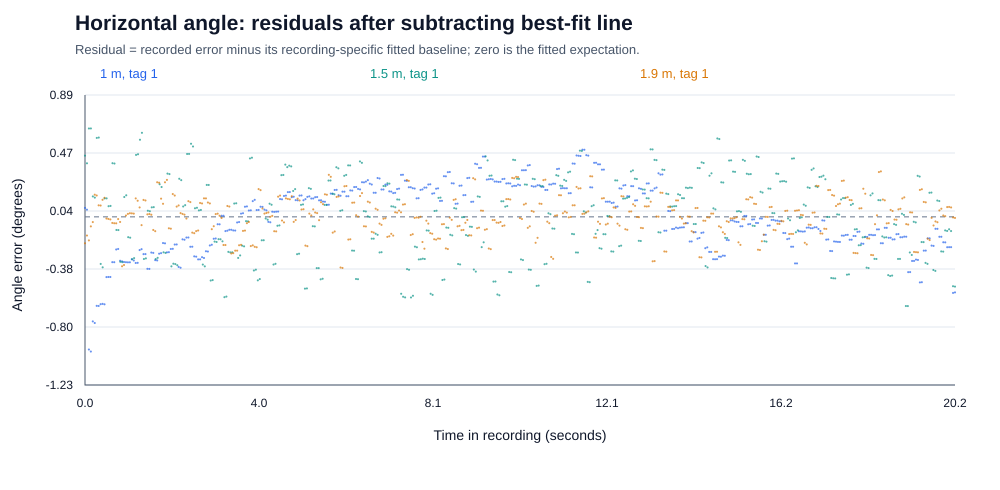

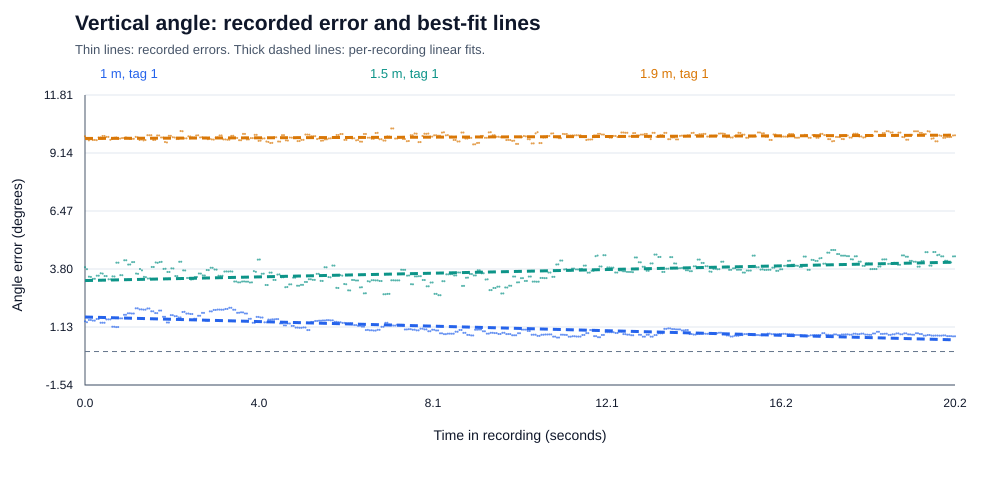

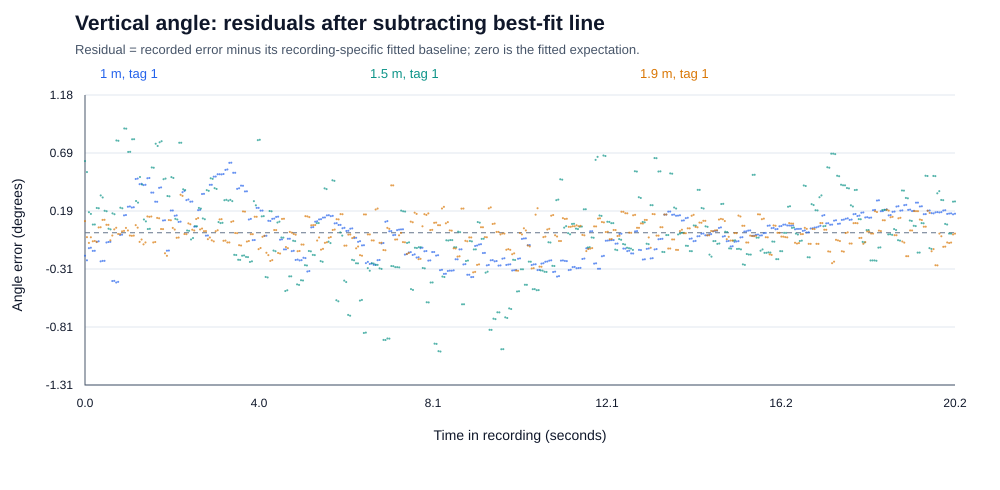

Axis,Distance (m),Samples,Mean bias (deg),Raw SD (deg),After mean removal SD (deg),Fitted drift (deg/s),Detrended residual SD (deg)
Horizontal,1.0,447,2.949,0.245,0.245,-0.00236,0.245
Horizontal,1.5,444,2.180,0.354,0.354,0.03417,0.292
Horizontal,1.9,447,4.057,0.227,0.227,0.03083,0.138
Vertical,1.0,447,1.064,0.372,0.372,-0.05199,0.214
Vertical,1.5,444,3.691,0.442,0.442,0.04186,0.367
Vertical,1.9,447,9.886,0.127,0.127,0.00752,0.119
Horizontal,Total,1338,3.064,0.820,0.281,Separate fits,0.234
Vertical,Total,1338,4.883,3.718,0.341,Separate fits,0.255


In [10]:
from detrend import linear_detrend

fit_records = []
fit_summary = []
for axis in ['horizontal','vertical']:
    metric = axis+'_angle_error_deg'
    by_clip = {}
    for row in rows:
        if row['status'] == 'ok':
            by_clip.setdefault((row['case'],row['tag_id']),[]).append(row)
    for (case,tag_id), samples in sorted(by_clip.items()):
        samples = sorted(samples,key=lambda r:r['frame'])
        t = np.array([r['video_time_s'] for r in samples])
        error = np.array([r[metric] for r in samples])
        fit = linear_detrend(t,error)
        fit_summary.append({'axis':axis,'case':case,'tag_id':int(tag_id),
            'distance_m':samples[0]['distance_m'],'samples':len(samples),
            'mean_offset_deg':float(error.mean()),'raw_sd_deg':sd(error),
            'demeaned_sd_deg':sd(fit['demeaned']),
            'drift_deg_per_s':fit['slope_deg_per_s'],'fit_intercept_deg':fit['intercept_deg'],
            'fit_time_origin_s':fit['time_origin_s'],
            'detrended_sd_deg':sd(fit['residuals'])})
        for row,raw,fitted,residual,demeaned in zip(samples,error,fit['fitted'],fit['residuals'],fit['demeaned']):
            fit_records.append({'axis':axis,'case':case,'tag_id':int(tag_id),
                'distance_m':row['distance_m'],'frame':int(row['frame']),
                'video_time_s':row['video_time_s'],'raw_error_deg':float(raw),
                'fitted_baseline_deg':float(fitted),'demeaned_error_deg':float(demeaned),
                'detrended_error_deg':float(residual)})

for axis in ['horizontal','vertical']:
    records = [r for r in fit_records if r['axis']==axis]
    raw = np.array([r['raw_error_deg'] for r in records])
    demeaned = np.array([r['demeaned_error_deg'] for r in records])
    residual = np.array([r['detrended_error_deg'] for r in records])
    fit_summary.append({'axis':axis,'case':'Total (separate fits per recording)',
        'tag_id':'','distance_m':'Total','samples':len(records),
        'mean_offset_deg':float(raw.mean()),'raw_sd_deg':sd(raw),
        'demeaned_sd_deg':sd(demeaned),'drift_deg_per_s':'','fit_intercept_deg':'',
        'fit_time_origin_s':'','detrended_sd_deg':sd(residual)})

for filename, records in [('angle_detrending_summary.csv',fit_summary),
                          ('angle_detrending_frames.csv',fit_records)]:
    with (RUN_DIRECTORY / filename).open('w',newline='') as stream:
        writer = csv.DictWriter(stream,fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)

for axis in ['horizontal','vertical']:
    axis_rows = [r for r in fit_records if r['axis']==axis]
    by_clip = {}
    for row in axis_rows:
        by_clip.setdefault((row['case'],row['tag_id']),[]).append(row)
    for residual_mode in [False,True]:
        key = 'detrended_error_deg' if residual_mode else 'raw_error_deg'
        data = [r[key] for r in axis_rows]
        low,high = min(0.,min(data)),max(0.,max(data))
        padding = max((high-low)*.15,.03)
        title = f'{axis.title()} angle: '+('residuals after subtracting best-fit line' if residual_mode else 'recorded error and best-fit lines')
        subtitle = ('Residual = recorded error minus its recording-specific fitted baseline; zero is the fitted expectation.'
                    if residual_mode else 'Thin lines: recorded errors. Thick dashed lines: per-recording linear fits.')
        parts = base_svg(title,subtitle)
        xmax = max(r['video_time_s'] for r in axis_rows)
        xp,yp = axes(parts,low-padding,high+padding,'Angle error (degrees)',0,xmax,'Time in recording (seconds)')
        for i,((case,tag_id),records) in enumerate(sorted(by_clip.items())):
            records = sorted(records,key=lambda r:r['frame'])
            color = COLORS[i%len(COLORS)]
            distance = records[0]['distance_m']
            parts.append(f'<text x="{100+i*270}" y="78" font-size="13" fill="{color}">{distance:g} m, tag {tag_id:g}</text>')
            # Scatter preserves gaps when detections are missing.
            for record in records:
                parts.append(f'<circle cx="{xp(record["video_time_s"]):.2f}" cy="{yp(record[key]):.2f}" r="1.05" fill="{color}" opacity="0.7"/>')
            if not residual_mode:
                first,last = records[0],records[-1]
                parts.append(f'<path d="M{xp(first["video_time_s"]):.2f} {yp(first["fitted_baseline_deg"]):.2f} L{xp(last["video_time_s"]):.2f} {yp(last["fitted_baseline_deg"]):.2f}" stroke="{color}" stroke-width="3" stroke-dasharray="8 5"/>')
        parts.append('</g></svg>')
        suffix = 'detrended' if residual_mode else 'best_fit'
        render_svg(''.join(parts),f'{axis}_angle_{suffix}_time.svg')

table = []
for record in fit_summary:
    drift = record['drift_deg_per_s']
    table.append([record['axis'].title(),record['distance_m'],record['samples'],
        f'{record["mean_offset_deg"]:.3f}',f'{record["raw_sd_deg"]:.3f}',
        f'{record["demeaned_sd_deg"]:.3f}',f'{drift:.5f}' if drift!='' else 'Separate fits',
        f'{record["detrended_sd_deg"]:.3f}'])
render_table(['Axis','Distance (m)','Samples','Mean bias (deg)','Raw SD (deg)',
              'After mean removal SD (deg)','Fitted drift (deg/s)',
              'Detrended residual SD (deg)'],table)
print('Diagnostic exports: angle_detrending_summary.csv and angle_detrending_frames.csv')


## 8. Relative angle error — each best-fit line is zero

This chart uses **each recording's own fitted line as its zero-error reference**:

`relative angle error(t) = measured angle error(t) − best-fit angle error(t)`

The thick horizontal **0° line** represents all the fitted baselines after
subtraction. Values above/below it show deviations from that recording's expected
trend, in degrees (not percent). Both panels use the same Y scale so horizontal
and vertical variation can be compared directly. The original offsets have not
been changed; this is a separate view of relative variation.

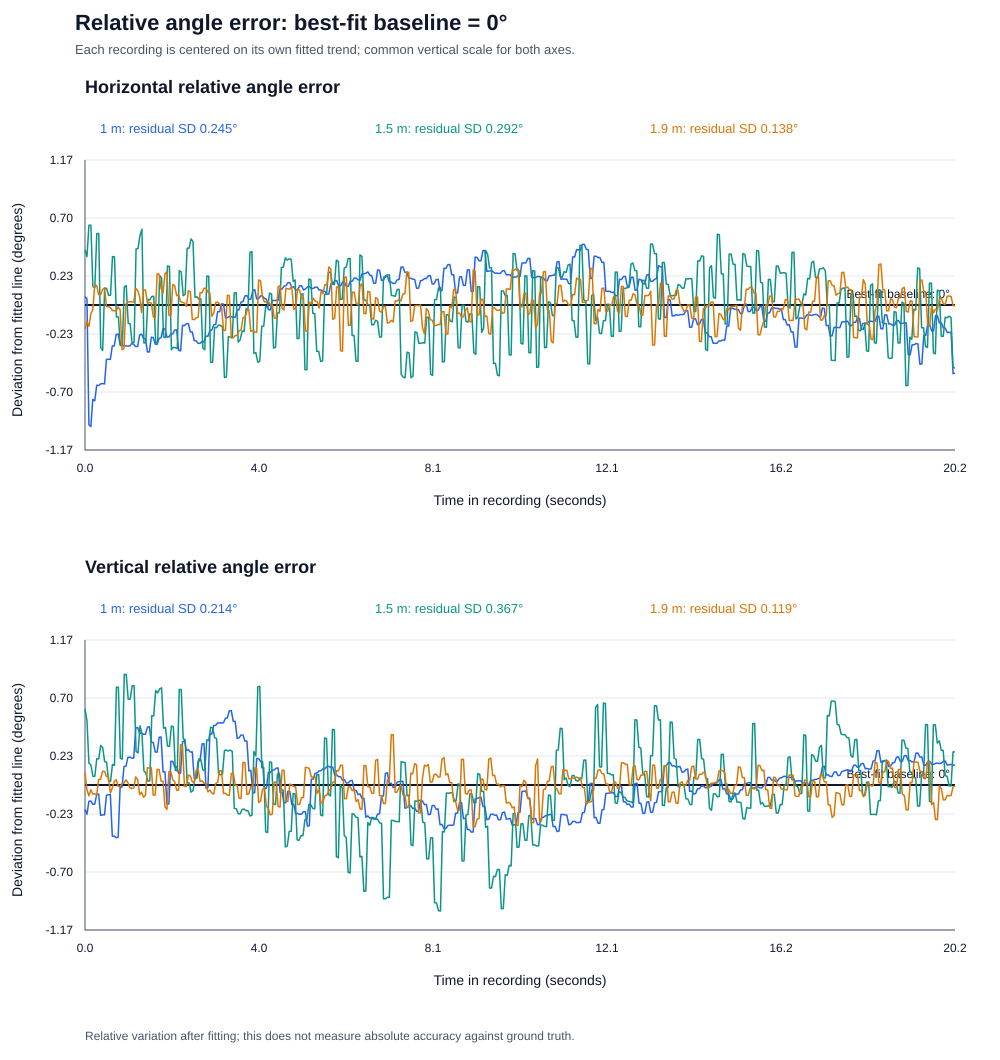

In [11]:
# Explicit zero-baseline view, using the already-computed per-recording residuals.
bound = max(abs(r['detrended_error_deg']) for r in fit_records)*1.15
bound = max(bound, .05)
xmax = max(r['video_time_s'] for r in fit_records)
parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="1060" viewBox="0 0 1000 1060">',
         '<rect width="1000" height="1060" fill="white"/>',
         '<g font-family="Arial,sans-serif" fill="#0f172a">',
         '<text x="75" y="30" font-size="22" font-weight="bold">Relative angle error: best-fit baseline = 0°</text>',
         '<text x="75" y="54" font-size="13" fill="#475569">Each recording is centered on its own fitted trend; common vertical scale for both axes.</text>']
for panel, axis in enumerate(['horizontal','vertical']):
    parts.append(f'<g transform="translate(0,{65+panel*480})">')
    parts.append(f'<text x="85" y="28" font-size="18" font-weight="bold">{axis.title()} relative angle error</text>')
    xp,yp = axes(parts,-bound,bound,'Deviation from fitted line (degrees)',0,xmax,'Time in recording (seconds)')
    # Explicitly render the baseline even if future axis limits or tick grids change.
    parts.append(f'<path d="M85 {yp(0)} H955" stroke="#0f172a" stroke-width="2"/>')
    parts.append(f'<text x="950" y="{yp(0)-7}" text-anchor="end" font-size="12" fill="#0f172a">Best-fit baseline: 0°</text>')
    by_clip = {}
    for row in fit_records:
        if row['axis']==axis:
            by_clip.setdefault((row['case'],row['tag_id']),[]).append(row)
    for i, ((case,tag_id),samples) in enumerate(sorted(by_clip.items())):
        color = COLORS[i%len(COLORS)]
        samples = sorted(samples,key=lambda r:r['frame'])
        distance = samples[0]['distance_m']
        data = np.array([r['detrended_error_deg'] for r in samples])
        parts.append(f'<text x="{100+i*275}" y="68" font-size="13" fill="{color}">{distance:g} m: residual SD {sd(data):.3f}°</text>')
        points = ' '.join(f'{xp(sample["video_time_s"]):.2f},{yp(sample["detrended_error_deg"]):.2f}' for sample in samples)
        parts.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="1.5" stroke-linejoin="round"/>')
    parts.append('</g>')
parts.append('<text x="85" y="1040" font-size="12" fill="#475569">Relative variation after fitting; this does not measure absolute accuracy against ground truth.</text></g></svg>')
render_svg(''.join(parts),'relative_angle_error_zero_baseline.svg')


## 9. Absolute relative angle error

The same fitted-baseline residuals are shown as magnitudes:
`absolute relative error(t) = |measured angle error(t) − best-fit line(t)|`.
Each distance label reports its **mean absolute residual** in degrees. This is
the average deviation from the fitted baseline, not the original signed bias
against ground truth. Horizontal and vertical panels use the same vertical scale.

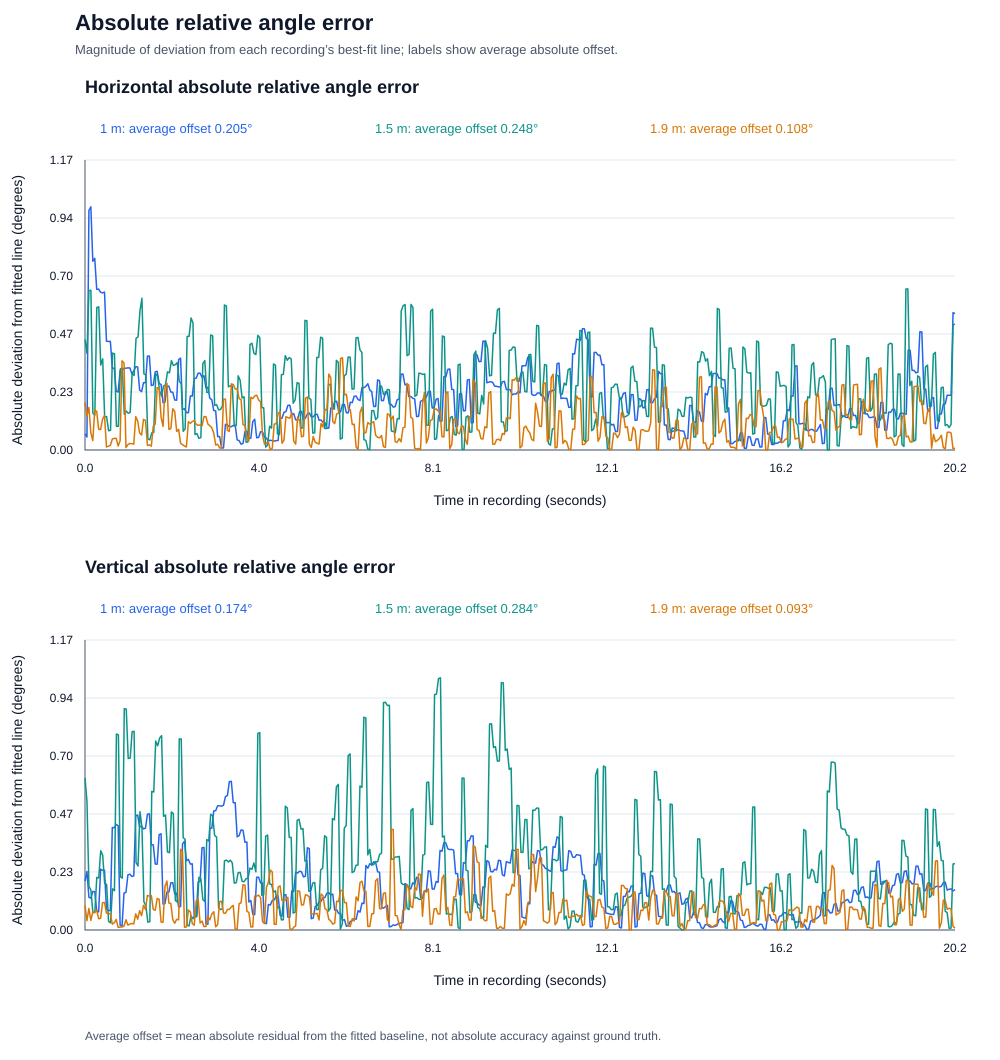

In [12]:
upper = max(abs(r['detrended_error_deg']) for r in fit_records)*1.15
upper = max(upper,.05)
xmax = max(r['video_time_s'] for r in fit_records)
parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="1060" viewBox="0 0 1000 1060">',
         '<rect width="1000" height="1060" fill="white"/>',
         '<g font-family="Arial,sans-serif" fill="#0f172a">',
         '<text x="75" y="30" font-size="22" font-weight="bold">Absolute relative angle error</text>',
         '<text x="75" y="54" font-size="13" fill="#475569">Magnitude of deviation from each recording’s best-fit line; labels show average absolute offset.</text>']
for panel,axis in enumerate(['horizontal','vertical']):
    parts.append(f'<g transform="translate(0,{65+panel*480})">')
    parts.append(f'<text x="85" y="28" font-size="18" font-weight="bold">{axis.title()} absolute relative angle error</text>')
    xp,yp = axes(parts,0,upper,'Absolute deviation from fitted line (degrees)',0,xmax,'Time in recording (seconds)')
    by_clip = {}
    for row in fit_records:
        if row['axis']==axis:
            by_clip.setdefault((row['case'],row['tag_id']),[]).append(row)
    for i,((case,tag_id),samples) in enumerate(sorted(by_clip.items())):
        color = COLORS[i%len(COLORS)]
        samples = sorted(samples,key=lambda r:r['frame'])
        distance = samples[0]['distance_m']
        mean_absolute = float(np.mean([abs(r['detrended_error_deg']) for r in samples]))
        parts.append(f'<text x="{100+i*275}" y="68" font-size="13" fill="{color}">{distance:g} m: average offset {mean_absolute:.3f}°</text>')
        points = ' '.join(f'{xp(r["video_time_s"]):.2f},{yp(abs(r["detrended_error_deg"])):.2f}' for r in samples)
        parts.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="1.5" stroke-linejoin="round"/>')
    parts.append('</g>')
parts.append('<text x="85" y="1040" font-size="12" fill="#475569">Average offset = mean absolute residual from the fitted baseline, not absolute accuracy against ground truth.</text></g></svg>')
render_svg(''.join(parts),'absolute_relative_angle_error.svg')


## Reading the results responsibly

Compare mean bias, SD, P95 and detection success together. The supplied positive
clips can establish descriptive reliability for **these conditions**, not a
deployment-wide reliability guarantee. Calibration error, uncertainty in tag size,
camera height and angle can explain repeatable bias that a tiny SD will not capture.

Useful next data: measured checkerboard calibration at this recording resolution,
repeat placements at each distance, multiple IDs, angled views and negative scenes.
The raw evidence remains in `frames.csv`; `summary.json` records parameters and
camera-calibration provenance. This notebook never refits camera parameters to
make the test errors smaller.